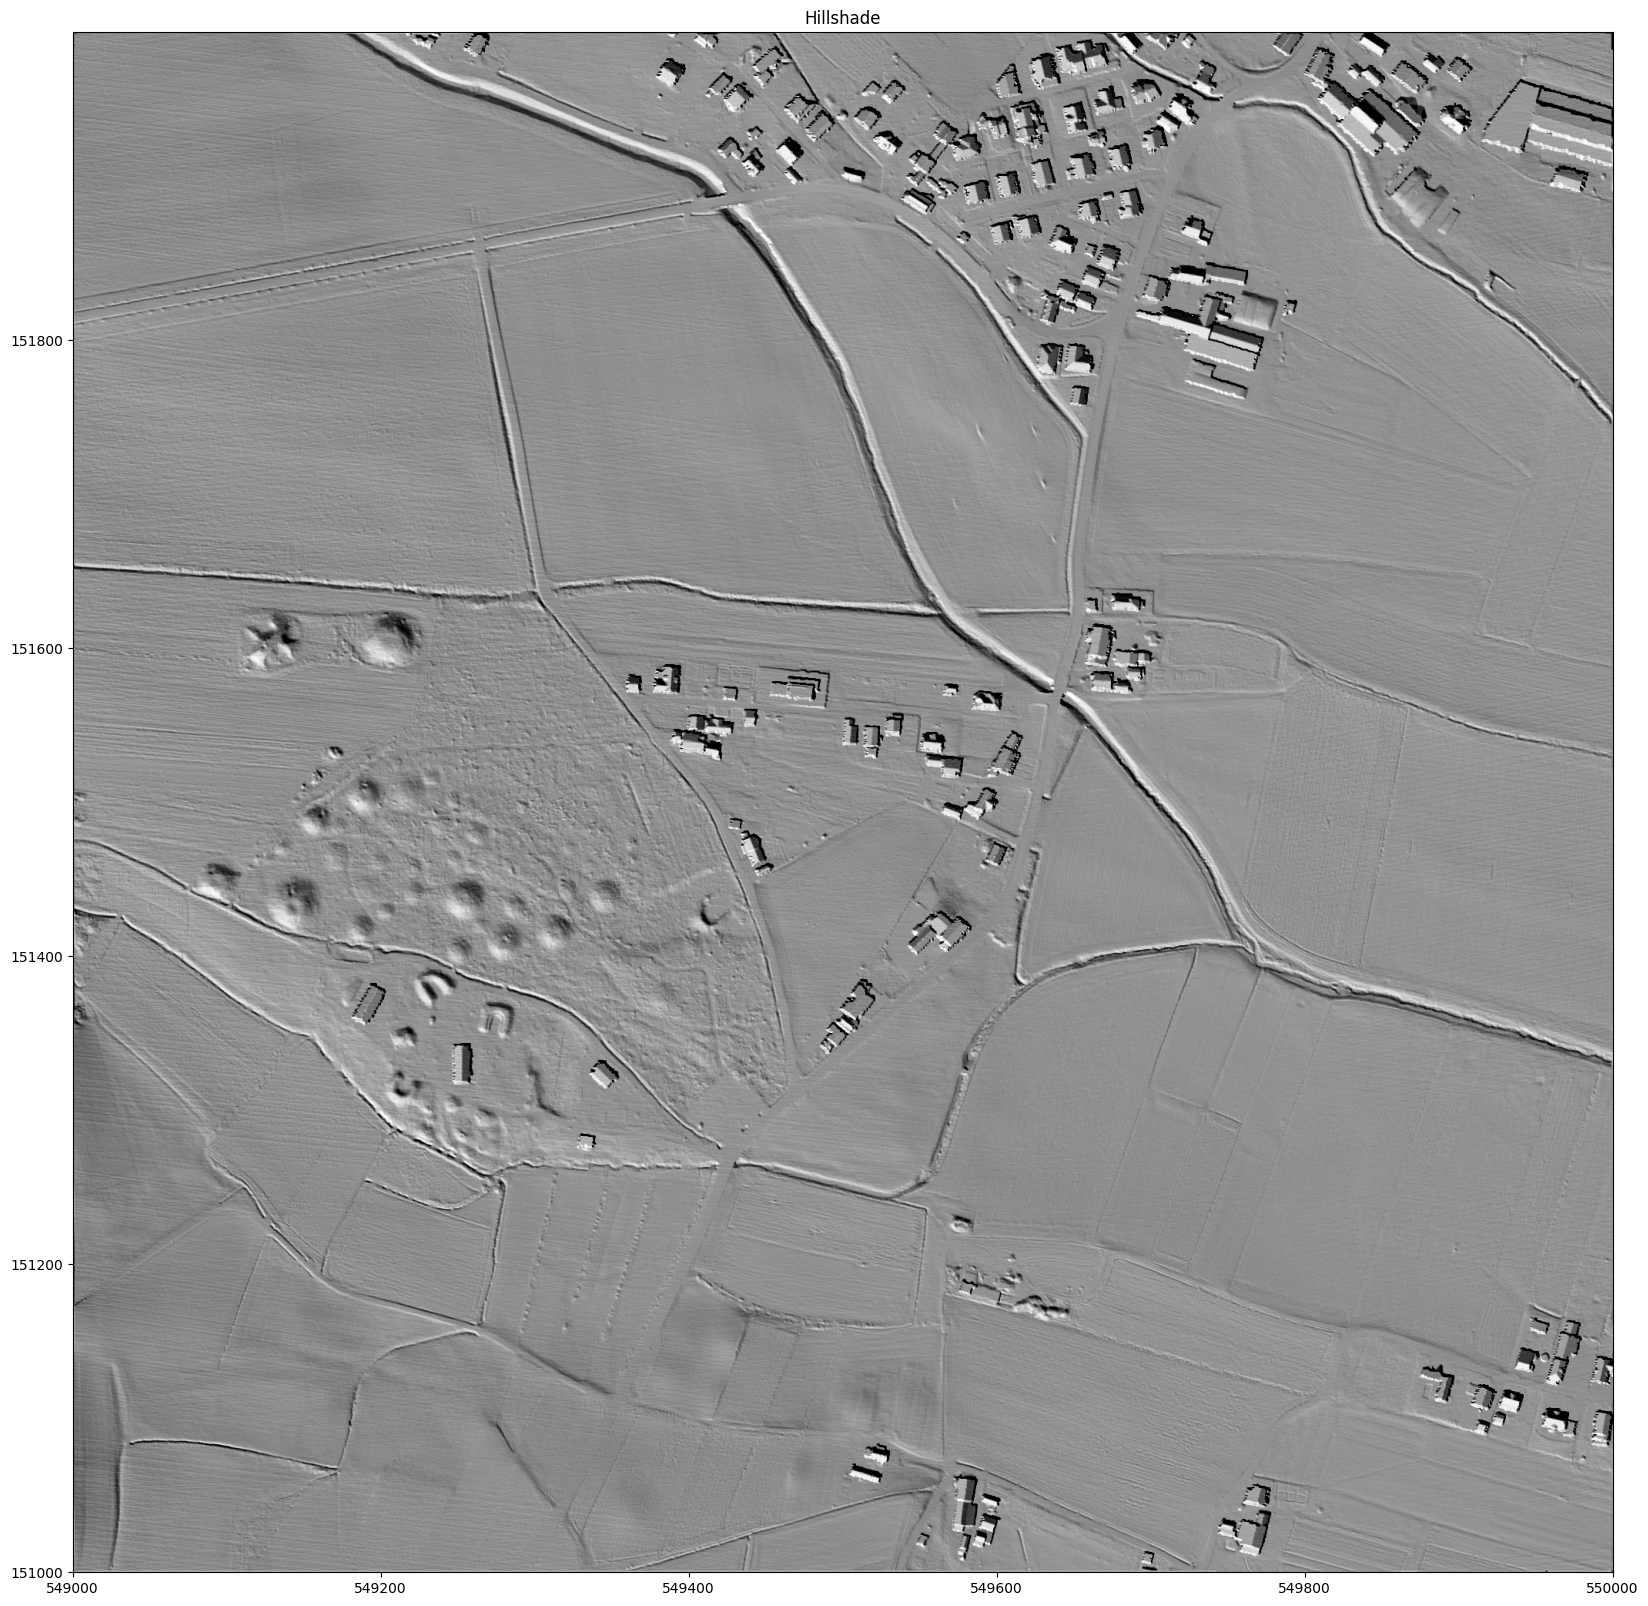

In [1]:
'''
Avtor / Author: Jaka Dacar 
Nazadnje spremenjeno / Last changed: 25.10.2026

Ta algoritem je uporabljen za uporabo vizualizacijske tehnike - senčenja oz. hillshade (v nadaljevanju bom uporabil besedo 'hillshade')
That algorithm was made for visualisation tecnique - hillshade (in continute, I will use word 'hillshade')


Algoritem je bil ustvarjen v sklopu diplomske naloge 
Algorithm was made as part of bachelor thesis
'''

import numpy as np
import rasterio as rio 
import matplotlib.pyplot as plt
from pathlib import Path 

#-----------------------------------------------------------------------------------------------------------------------------------
#INPUT in OUTPUT
#-----------------------------------------------------------------------------------------------------------------------------------
#vhod pot podatka, za 2katero imaš namen uporabiti za hillshade. Datoteka mora biti nujno shranjena pod .tiff ali .tif
src_path = Path(r"C:\Users\jakad\OneDrive\Desktop\3d_data\output\Pivola_klasificirano_in_rastirano.tiff")

#izhod podatkov, kjer se bo shranila v prostoru, kjer je definiran pot. Datoteka, naj se shrani pod .tiff (bolj priročno) ali .tif 
src_out_path = Path(r"C:\Users\jakad\OneDrive\Desktop\3d_data\output\Moj_hillšajd9.tiff")

#-----------------------------------------------------------------------------------------------------------------------------------
#DODATNO TEMNENJE ali SVETLJENJE 
#-----------------------------------------------------------------------------------------------------------------------------------
#to je orodje, ki se uporablja tudi v okolju QGIS. Gre za namerno dodatno senčenje med dve razmerjema, ki ju daš pod min in max
#vključi dirketno v hillshade (če želiš, ampak zaenkrat ni potrebe)
def cumulative_count_cut(band, min_percentile=2, max_percentile=98):
    min_val = np.nanpercentile(band, min_percentile)
    max_val = np.nanpercentile(band, max_percentile)
    
    return min_val, max_val

#-----------------------------------------------------------------------------------------------------------------------------------
#HILLSHADE
#-----------------------------------------------------------------------------------------------------------------------------------
def hillshade(
            dtm, 
            azimuth=215, 
            altitude=35, 
            cellsize_x=0.5, 
            cellsize_y=0.5
        ):

#gre za uporabo matrike oz. polja, kjer so definiranii zgolj robovi (zato osrednjega dela ni potrebno posebej definirati). Nato je prisoten matematičen izračuna:
#dz_dx (navpičen del oz. vzhod-zahod) in dz_dy (vodoraven del oz. sever-jug), ki sta splošno znana v uporabi raster datoteke. 
    p = np.pad(dtm, 1, mode="edge")
    a, b, c = p[:-2, :-2], p[:-2, 1:-1], p[:-2, 2:]
    d,    f = p[1:-1, :-2],              p[1:-1, 2:]
    g, h, i = p[2:, :-2],  p[2:, 1:-1],  p[2:, 2:]

#naklon po Hornovi metodi (1981), metrika z 3x3 okno. 
    dz_dx = ((c + 2 * f + i) - (a + 2 * d + g)) / (8 * cellsize_x)
    dz_dy = ((g + 2 * h + i) - (a + 2 * b + c)) / (8 * cellsize_y)

#za izračunajne radija. Sicer pa gre za izračun kompasnega azimuta; 0° je usmrejen proti severu, ki gre nato v smeri urinega kazalca. 
#medtem v matematiki pa je usmrejeno proti 0° usmrejno proti vzhodu in gre v nasportnem delu urinega kazalca
    azimuth_rad = np.radians(360.0 - azimuth + 90.0)
    zenith_rad = np.radians(90.0 - altitude)

    slope = np.arctan(np.hypot(dz_dx, dz_dy))
    aspect = np.arctan2(dz_dy, -dz_dx)

#senčenje s pomočjo trigonometrije - gre za splošno sprejeto formulo
    shaded = (
        np.cos(zenith_rad) * 
        np.cos(slope) +
        np.sin(zenith_rad) * 
        np.sin(slope) * 
        np.cos(azimuth_rad - aspect)
    )

#vrednost se nato omeji na razpon 0-1, ki jih nato pretvori na razpon 0-255 in shrani kot 32-bitna slika 
    hs = (255 * np.clip(shaded, 0, 1)).astype(np.float32)

    return hs
#-----------------------------------------------------------------------------------------------------------------------------------
#ZADNJI DEL in SHRANJEVANJE DATOTEKE 
#-----------------------------------------------------------------------------------------------------------------------------------
with rio.open(src_path) as src:
    dtm = src.read(1)
    profile = src.profile
    res_x, res_y = src.res
    ext = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]

hs = hillshade(
    dtm=dtm,
    azimuth=215,
    altitude=35,
    cellsize_x=res_x,
    cellsize_y=res_y
)

if src_out_path is not None:
    if profile is None:
        raise ValueError("Za shranjevanje moraš podati profile.")
    out_profile = profile.copy()
    out_profile.update(dtype="float64", count=1, compress="lzw", nodata=None)
    with rio.open(src_out_path, "w", **out_profile) as dst:
        dst.write(hs, 1)

#-----------------------------------------------------------------------------------------------------------------------------------
#HITER PRIKAZ HILLSHADE-ja Z MATPLOTLIB-om
#-----------------------------------------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(20, 20))
im = ax.imshow(hs, cmap='gray', extent=ext)
ax.set_title("Hillshade")
plt.show()